In [1]:
# conda env 'at3d_pure_k9'
"""This notebook runs space carving for a given RTE grid and set of 
AT3D observations with brf thresholds.

Generates SC*.nc
"""
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'

import sys
sys.path.append(str(PROJECT_ROOT))

import at3d
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import netCDF4 as nc
import src.utils.util as util

In [2]:
def plot_measurements(sensor_dict, instrument, fig, ax, s=2):
    sensor_list = sensor_dict[instrument]['sensor_list']
    for i, cam in enumerate(sensor_list):
        z = np.unique(cam.ray_z.data)
        if(len(z) == 1):
            title = '{}\nz={} km'.format(cam.name, z[0])
        else:
            title = '{}\nz=non-uniform'.format(cam.name)
        ax[i].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=cam.I.data*np.pi/cam.mu0, marker='s', cmap='gray')
        ax[i].set_title(title)

def plot_mask(sensor_dict, instrument, fig, ax, s=2):
    sensor_list = sensor_dict[instrument]['sensor_list']
    for i, cam in enumerate(sensor_list):
        z = np.unique(cam.ray_z.data)
        if(len(z) == 1):
            title = '{}\nz={} km'.format(cam.name, z[0])
        else:
            title = '{}\nz=non-uniform'.format(cam.name)
        ax[i].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=cam.cloud_mask.data, vmin=0, vmax=1, marker='s', cmap='gray')
        ax[i].set_title(title)

In [3]:
## INPUT
# RT Grid
rte_grid_file = INTERIM_DATA / 'RTG_default.nc'
# AT3D Observation
obs_file = INTERIM_DATA / 'AT3D_OBS_CAMP2Ex_RF17_default.nc'
# Thresholds
thresholds = [0.120, 0.076, 0.054, 0.044, 0.040, 0.045, 0.052, 0.068, 0.092]
# Agreement
agreement = (0, 2/9)

## OUTPUT
out_file = INTERIM_DATA / 'SC_CAMP2Ex_RF17_default.nc'

In [4]:
rte_grid = xr.load_dataset(rte_grid_file)
measurements = util.load_sensor_dict(obs_file)

In [5]:
masked_sensors = at3d.containers.SensorsDict()
for i, sensor in enumerate(measurements['MISR']['sensor_list']):
    sensor_copy = sensor.copy(deep=True)
    mask = np.zeros(sensor.dims['nrays'])
    mask[sensor_copy.I.data*np.pi/sensor_copy.mu0 > thresholds[i]] = 1
    sensor_copy['cloud_mask'] = (['nrays'], mask)
    masked_sensors.add_sensor('MISR', sensor_copy)

In [6]:
space_carver = at3d.space_carve.SpaceCarver(rte_grid, bcflag=3)
carved_volume = space_carver.carve(masked_sensors, agreement=agreement, linear_mode=False)
carved_volume['rel_cloudy'] = carved_volume.cloudy_counts / carved_volume.total_counts
assert np.sum(carved_volume.total_counts.data == 0) == 0, "{} voxels without rays".format(np.sum(carved_volume.total_counts.data == 0))
# carved_volume.to_netcdf(out_file)

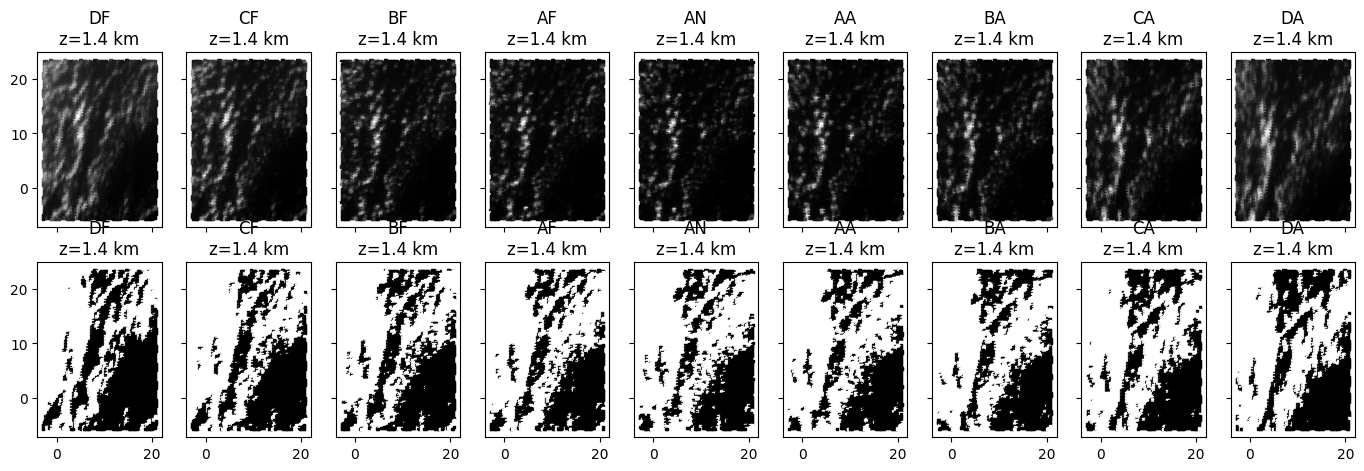

In [10]:
fig, ax = plt.subplots(2, 9, figsize=(17, 5), sharex=True, sharey=True)
plot_measurements(measurements, 'MISR', fig, ax[0,:], s=2)
plot_mask(masked_sensors, 'MISR', fig, ax[1,:], s=2)

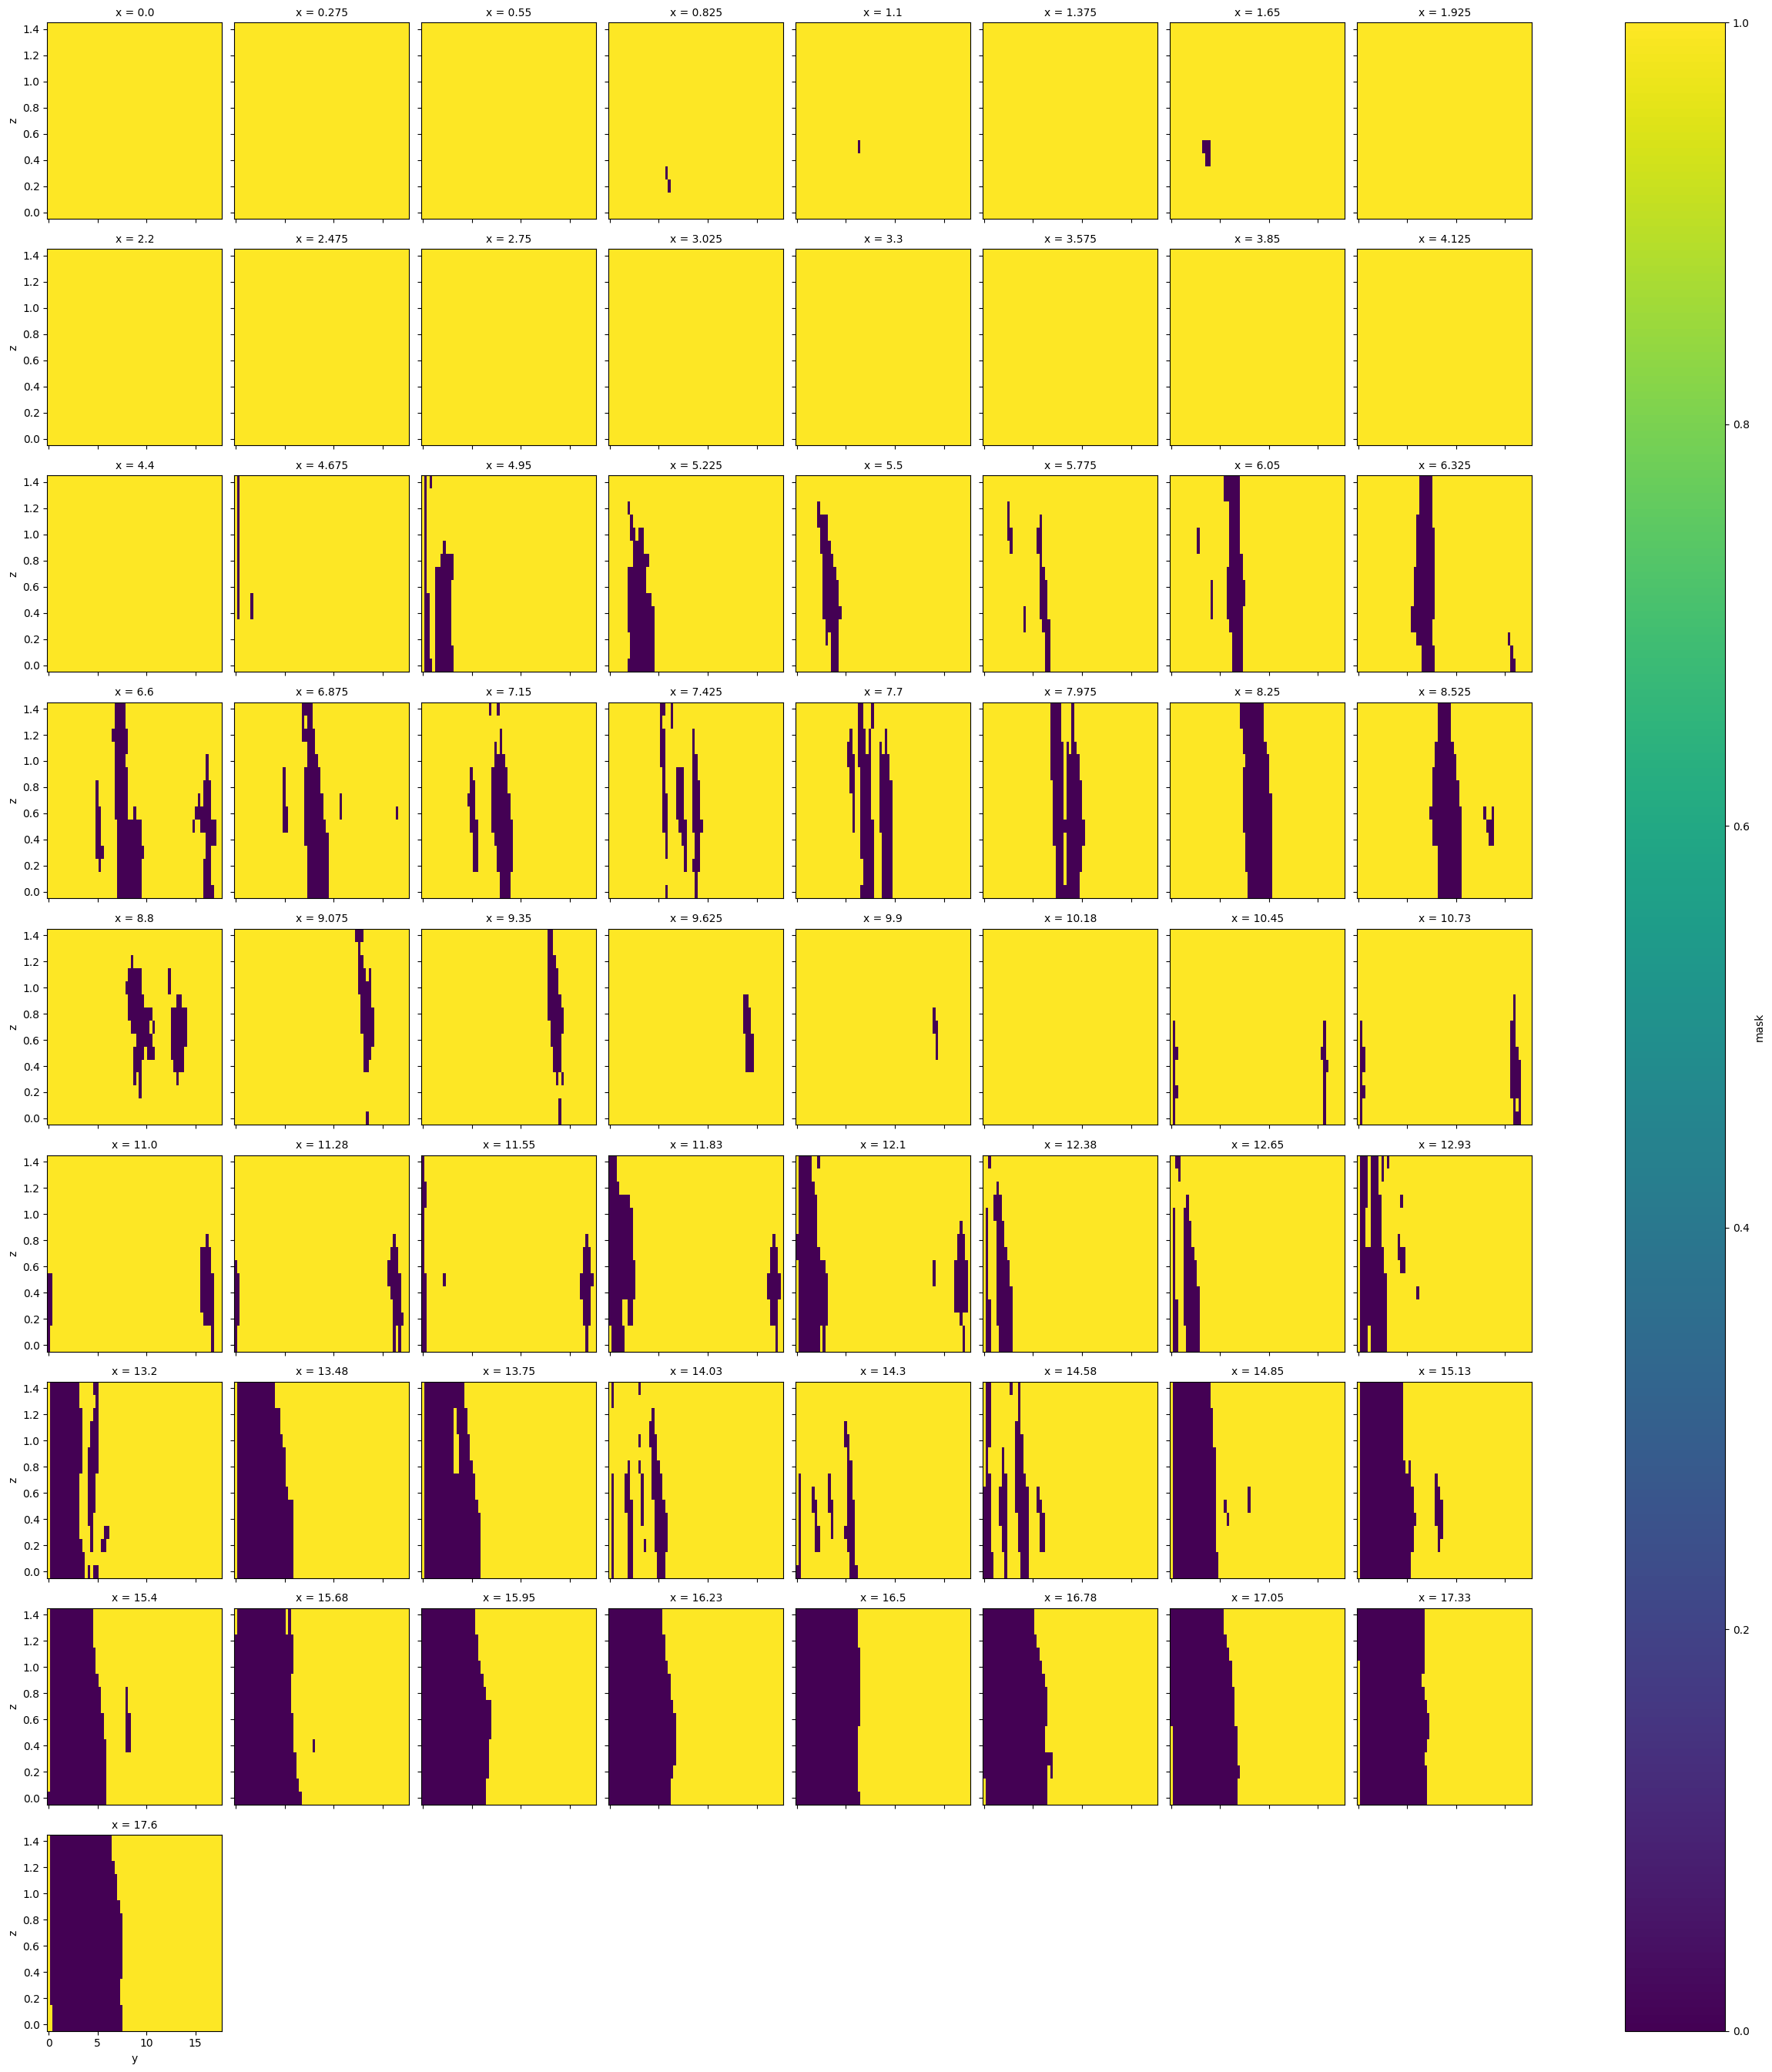

In [8]:
carved_volume.mask.plot(y='z', x='y', col='x', col_wrap=8)

In [9]:
# carved_volume.mask.isel(x=slice(0,None,4)).plot(x='y',y='z', col='x', col_wrap=5, cmap='gray')